# UI optimization: organising a student's prompts into a forest

HCI 2026, group 19 (Arbor), Milestone 3. An integer program, solved with Gurobi, decides where a
new prompt goes in the student's knowledge forest, and when the forest should reorganise.

This notebook runs top to bottom from the cached inputs in `data/frozen/`. It needs no API key,
downloads no model and makes no LLM call: `REQUIRE_CACHED` below turns any cache miss into an
error. Dependencies: `requirements.txt` in this folder. The code lives in `forest/`, next to this
notebook. The research notebooks `notebooks/01` to `06` hold the full analysis.

In [1]:
import sys
from itertools import product
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from forest import cache, config, viz
from forest.config import IPParams
from forest.export import export_sequence
from forest.io import SESSION_IDS, load_gold, load_sessions, read_jsonl, write_json
from forest.ip import ACTION_NAMES, place
from forest.simulate import compare, make_context, trace_ip

cache.REQUIRE_CACHED = True   # no model load, no API call: everything comes from data/frozen/
viz.style()
pd.set_option("display.width", 180)
cfg = config.load()
ctx = make_context(cfg)
P = ctx.params
sessions = load_sessions()
golds = {sid: load_gold(sid) for sid in SESSION_IDS}
SESSION = "s1_focused"
FIG, FOR = Path(cfg["paths"]["figures"]), Path(cfg["paths"]["forests"])
print("judge:", ctx.judge.backend, ctx.judge.model, "| embeddings:", ctx.emb.model)

judge: offline offline-heuristic-v1 | embeddings: sentence-transformers/all-MiniLM-L6-v2


## 1. The problem

A tutor chat collects many prompts. Arbor organises them into a **forest**: **groups** (subjects)
hold **trees** of **topics**, and every prompt hangs on one topic. A topic whose parent is a group
is a tree root; otherwise its parent is another topic. When a new prompt arrives there are five
possible outcomes:

| | Outcome | Meaning |
|---|---|---|
| (a) | add | the prompt goes into an existing topic |
| (b) | new branch | a new topic under an existing topic |
| (c) | new tree | a new topic directly under an existing group |
| (d) | new group | a new group with a new tree |
| (e) | rebalance | existing prompts or topics move, merge, split, are deleted or renamed |

One placement step runs this pipeline:

```
new prompt -> [1. judge (scores + candidate names), on the whole forest]
           -> [2. scores: judge mixed with embedding cosine] -> [3. integer program (Gurobi)]
           -> [4. new forest + action]
```

The judge never decides. It rates fits and proposes candidate topics, groups and renames. The IP
decides which categories exist, where they hang, where every prompt goes, and whether to
rebalance.

**Why it is not trivial.** "Put the prompt where it fits best" ignores four things the IP
prices: a topic that grows too large or stays too small, a tree that gets too deep or wide, the
cost of every new category, and the disruption of moving things the student has just seen. The
simulation (section 5) measures how often the IP disagrees with the judge's own top choice.

### Sets
$P$: prompts, $n$ the new one, $P_{old} = P \setminus \{n\}$. $C_T = C_T^{old} \cup C_T^{new}$:
topics, existing and proposed. $C_G = C_G^{old} \cup C_G^{new}$: groups. $R \subseteq C_T^{new}$:
rename candidates, each with $orig(r) \in C_T^{old}$.

### Parameters
$s_{pc} \in [0,1]$: fit of prompt $p$ to topic $c$, equal to $\gamma \cdot judge + (1-\gamma) \cdot$
calibrated cosine. $h_{c'c}$: fit of $c$ under topic $c'$. $hg_{gc}$: fit of the tree rooted at
$c$ in group $g$. $c_0(p)$ and $\pi_0(c)$: the previous topic of a prompt and parent of a
category. $w_p$ and $v_c$: disruption weights from recency of use,
$w_p = 1 + a\, e^{-(t - t^{last}_p)/T}$, with $v_c$ the maximum of $w$ over the subtree.
Limits $L, U$ (preferred content per topic), $B$ (subtopics), $D$ (depth), $K_T$ (trees per
group), $K_G$ (groups). Weights $\alpha, \alpha_G, \lambda, \lambda_G, \beta, \mu, \nu, \rho, F$.
Pruning threshold $\tau$.

### Variables
$y_c$ (category exists), $q_{pc}$ (prompt in topic), $x_{c'c}$ (topic under topic), $xg_{gc}$
(tree root in group): binary. $d_c \in \{0..D-1\}$: depth. $m_p$, $k_c$: prompt moved, category
re-parented or removed. $z$: any rebalance. $o_c, u_c, b_c \ge 0$: slack for too full, too sparse,
too many children.

### Objective (maximise)
$$\sum s_{pc} q_{pc} + \alpha \sum h_{c'c} x_{c'c} + \alpha_G \sum hg_{gc} xg_{gc}
  - \lambda \sum_{c \in C_T^{new} \setminus R} y_c - \lambda_G \sum_{g \in C_G^{new}} y_g
  - \beta \sum_c (o_c + u_c + b_c) - \mu \sum_p w_p m_p - \nu \sum_c v_c k_c
  - \rho \sum_{r \in R} v_{orig(r)} y_r - F z$$

### Constraints
- **C1** $\sum_c q_{pc} = 1$. **C2** $q_{pc} \le y_c$.
- **C3** $\sum_{c'} x_{c'c} + \sum_g xg_{gc} = y_c$. **C4** $x_{c'c} \le y_{c'}$, $xg_{gc} \le y_g$.
- **C5** $y_c \le \sum_p q_{pc} + \sum_{c''} x_{cc''}$ (no empty topics). **C6** $y_g \le \sum_c xg_{gc}$ (no empty groups).
- **C7** $d_c \ge d_{c'} + 1 - D(1 - x_{c'c})$ (depth, no cycles). **C8** $d_c \le (D-1)(1 - \sum_g xg_{gc})$.
- **C9** $\sum_p q_{pc} \le U + o_c$. **C10** $\sum_p q_{pc} + \sum_{c''} x_{cc''} \ge L y_c - u_c$. **C11** $\sum_{c''} x_{cc''} \le B + b_c$.
- **C12** $\sum_c xg_{gc} \le K_T$. **C13** $\sum_g y_g \le K_G$.
- **C14** $m_p \ge 1 - q_{p,c_0(p)}$. **C15** $k_c \ge 1 - x_{\pi_0(c),c}$ (or $xg$). **C16** $k_g \ge 1 - y_g$ for old groups. **C17** $m_p \le z$, $k_c \le z$.
- **C18** pruning: a pair is a variable only if its score is at least $\tau$. Every old link is kept,
  so "change nothing" is always feasible. There are also caps on alternatives per old prompt and
  parents per topic (for the size limit).
- Renames: **R1** $y_{orig} + y_r \le 1$. **R2** to **R4** treat staying in, or under, a renamed
  topic as no move. **R5** $y_r \le z$.

The action is read off as: (e) if $z = 1$ and something moved or was renamed; otherwise (a) if
$n$ is in an old topic, and (b), (c) or (d) by where the new topic hangs.

## 2. Parameters and their justification

In [2]:
why = {
    "L": "a topic with one prompt is barely a category",
    "U": "about what the sidebar shows without scrolling",
    "B": "sibling lists stay scannable",
    "D": "deeper trees make navigation slow",
    "K_T": "trees per group visible at once",
    "K_G": "groups visible at once",
    "alpha": "hierarchy matters, but less than prompt placement",
    "alpha_G": "same, for a tree in its group",
    "lam": "a new topic must gain 0.4 fit points",
    "lam_G": "plan start 1.0; below 1 + alpha_G - lam - beta(L-1) = 0.8, otherwise a new group can never pay off",
    "beta": "per unit of imbalance",
    "mu": "per weighted moved prompt",
    "nu": "moving a topic moves its whole subtree",
    "rho": "a rename is cheaper than a move",
    "F": "fixed cost of any visible reorganisation",
    "tau": "pruning threshold (C18)",
}
pd.DataFrame([{"parameter": k, "value": getattr(P, k), "why": v} for k, v in why.items()]
             + [{"parameter": "gamma", "value": cfg["scores"]["gamma"], "why": "judge weighted above the cosine"},
                {"parameter": "a, T", "value": f"{cfg['disruption']['a']}, {cfg['disruption']['T']}",
                 "why": "w = 1 + a exp(-age / T): a prompt used in the last few steps costs up to 3x to move"}]
             ).set_index("parameter")

,value,why
parameter,,
L,2,a topic with one prompt is barely a category
U,6,about what the sidebar shows without scrolling
B,5,sibling lists stay scannable
D,3,deeper trees make navigation slow
K_T,4,trees per group visible at once
K_G,5,groups visible at once
alpha,0.5,"hierarchy matters, but less than prompt placement"
alpha_G,0.5,"same, for a tree in its group"
lam,0.4,a new topic must gain 0.4 fit points


## 3. Inputs

`SESSION` is a scripted session of student prompts (a **draft** by Claude Opus 5.5, to be
reviewed by the group). The embedding model is `sentence-transformers/all-MiniLM-L6-v2`, chosen
in `notebooks/02` because its cosine finds the gold topic most often. The judge is the one printed above. With
`offline-heuristic-v1` the judge's fits are calibrated cosines, not an LLM: no LLM-derived
estimate enters these results until a live judge has been run and frozen (`notebooks/03`, model
and version are then printed above).

In [3]:
s = sessions[SESSION]
print(f"{SESSION}: {len(s.prompts)} prompts, {len(s.access_events)} re-open events; {s.description}")
pd.DataFrame([{"step": p.step, "text": p.text} for p in s.prompts]).head(8)

s1_focused: 30 prompts, 5 re-open events; One course (neural networks exercise sheet); many prompts on backpropagation, so topics overflow and splits become worthwhile.


,step,text
0,1,We're doing backprop on exercise sheet 4. Can ...
1,2,For a 2-layer MLP with sigmoid hidden units I ...
2,3,how does the chain rule work on a computationa...
3,4,Why do people use ReLU instead of sigmoid in h...
4,5,I computed the gradient of the loss wrt the bi...
5,6,what is the derivative of tanh? I think it's 1...
6,7,"In the computational graph for f = (x+y)*z, wh..."
7,8,Our network trains fine with 3 layers but with...


## 4. One step of the IP
We replay the session with the IP and pick the step whose decision depends most on the stability
weights. Section 6 shows that step across a grid of `mu` and `F`.

In [4]:
GRID = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
trace = trace_ip(s, ctx)
def sensitivity(t):
    acts = {place(t["input"], P.replace(mu=mu, F=F)).action for mu, F in product(GRID, GRID)}
    return (len(acts), "e" in acts, "b" in acts)
t = max(trace[2:], key=lambda t: (sensitivity(t), -t["prompt"].step))
before, n, res = t["before"], t["prompt"], t["result"]
print(f"step {n.step}: {n.text!r}\n")
print("judge fits (1-5):", {before.topics[e.topic_id].label: e.fit for e in t["view"].placement.existing})
print("judge proposals:", [(p.name, p.fit) for p in t["view"].placement.proposed])
print("\nmodel size:", {k: res.size[k] for k in ("vars", "constrs", "binary", "integer")},
      "(pip license limit: 2000 each)")
print("solve:", res.solution.status, f"{1000 * res.solution.runtime_s:.1f} ms, objective {res.solution.objective:.3f}")
print("action:", res.action, f"({ACTION_NAMES[res.action]}) -> n placed in", res.forest.path(res.topic_of_n))
print("changes:", {k: v for k, v in res.diff.items() if v})

Restricted license - for non-production use only - expires 2028-11-29


step 13: 'How do I do gradient checking with finite differences? What epsilon should I pick?'

judge fits (1-5): {'Backpropagation': 3, 'Layer Mlp': 2, 'Computational Graph': 2, 'Sigmoid in Hidden': 3, 'Local Gradients': 4, 'Derivative of Softmax': 3, 'Leaky Relu': 2}
judge proposals: [('Gradient Checking', 5), ('Finite Differences', 5)]

model size: {'vars': 179, 'constrs': 256, 'binary': 143, 'integer': 9} (pip license limit: 2000 each)
solve: optimal 3.9 ms, objective 12.679
action: b (new branch) -> n placed in Deep Learning > Local Gradients > Finite Differences
changes: {'new_topics': ['t13b']}


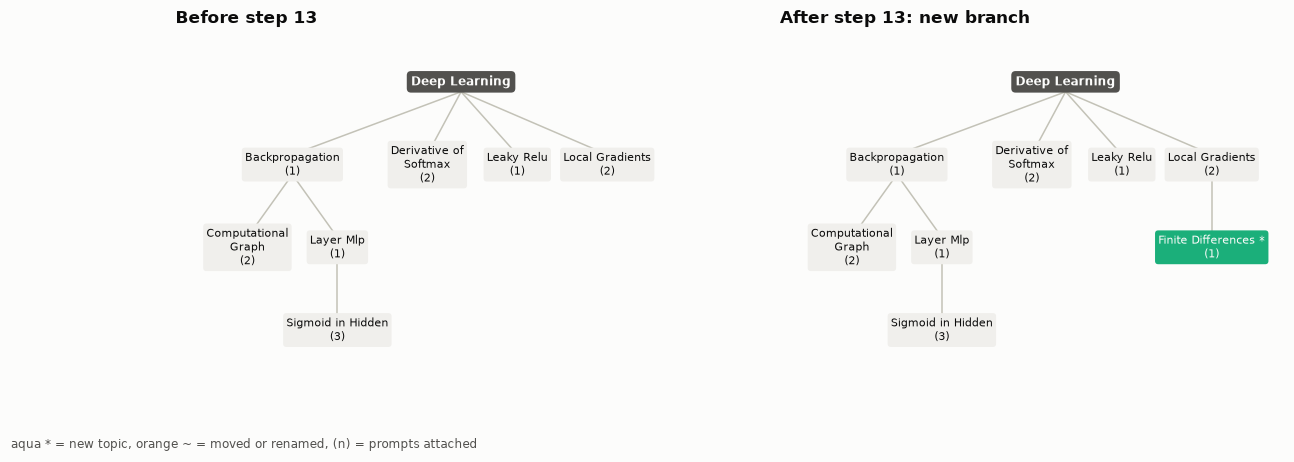

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
viz.plot_forest(before, axes[0], title=f"Before step {n.step}")
viz.plot_forest(res.forest, axes[1], title=f"After step {n.step}: {ACTION_NAMES[res.action]}",
                **viz.forest_change_sets(before, res.forest))
fig.text(0.01, -0.02, "aqua * = new topic, orange ~ = moved or renamed, (n) = prompts attached", fontsize=8,
         color=viz.TEXT_2)
plt.show()

## 5. The IP against the two human-made alternatives
- **chronological**: one tree per chat, prompts in order. This is the status quo of a chat sidebar.
- **greedy**: put the prompt in the best-fitting existing topic if its fit `s` is at least 0.55,
  otherwise open the judge's top proposed topic under its top-rated parent.

`judge_argmax` (the judge's highest-rated option, no IP) is shown as a reference.
`ip_differs_from_judge_argmax` is the share of steps where the IP decided differently from it,
given the same judge answer. Fit is the calibrated cosine of each prompt to its topic's label,
the same scorer for every method.

In [6]:
rows = []
for sid in SESSION_IDS:
    _, summ, forests = compare(["chronological", "greedy", "judge_argmax", "ip"], sessions[sid], ctx, golds[sid],
                               save_root=FOR if sid == SESSION else None)
    rows.append(summ)
    if sid == SESSION:
        session_forests = forests
table = pd.concat(rows, ignore_index=True)
cols = ["session", "method", "final_fit", "topics", "trees", "groups", "over_U", "under_L", "viol_K_T",
        "moved_prompts", "disruption_w", "ari_topic", "ip_differs_from_judge_argmax"]
table[cols].round(2).set_index(["session", "method"])

final_fit  topics  trees  groups  over_U  under_L  viol_K_T  moved_prompts  disruption_w  ari_topic  ip_differs_from_judge_argmax
session    method                                                                                                                                          
s1_focused chronological       8.42       2      2       1       2        0         0              0          0.00       0.01                           NaN
           greedy             26.82      15     12       2       0        6         7              0          0.00       0.41                           NaN
           judge_argmax       28.77      21     10       2       0       11         5              0          0.00       0.30                           NaN
           ip                 23.49      15      4       1       0        5         0              0          0.00       0.26                           0.5
s2_mixed   chronological       5.27       2      2       1       2        0         0              0          0.00      -0.02                           NaN
           greedy             26.12      19     18       3       0       11        12              0          0.00       0.41                           NaN
           judge_argmax       28.39      26     15       3       0       19         9              0          0.00       0.19                           NaN
           ip                 19.03      12      5       2       0        0         0              2          3.14       0.32                           0.6
s3_drift   chronological       7.34       2      2       1       2        0         0              0          0.00       0.20                           NaN
           greedy             23.61      17     15       2       0        9         9              0          0.00       0.51                           NaN
           judge_argmax       23.95      19     15       2       0       11         9              0          0.00       0.44                           NaN
           ip                 16.23      10      4       1       1        1         0              1          1.05       0.06                           0.8

## 6. What-if: the stability weights
**Sweep:** the whole session re-run with the IP for every pair of `mu` (cost per moved prompt) and
`F` (fixed cost of a rebalance). **Flip:** the step from section 4, re-solved over the same grid
with its state held fixed.

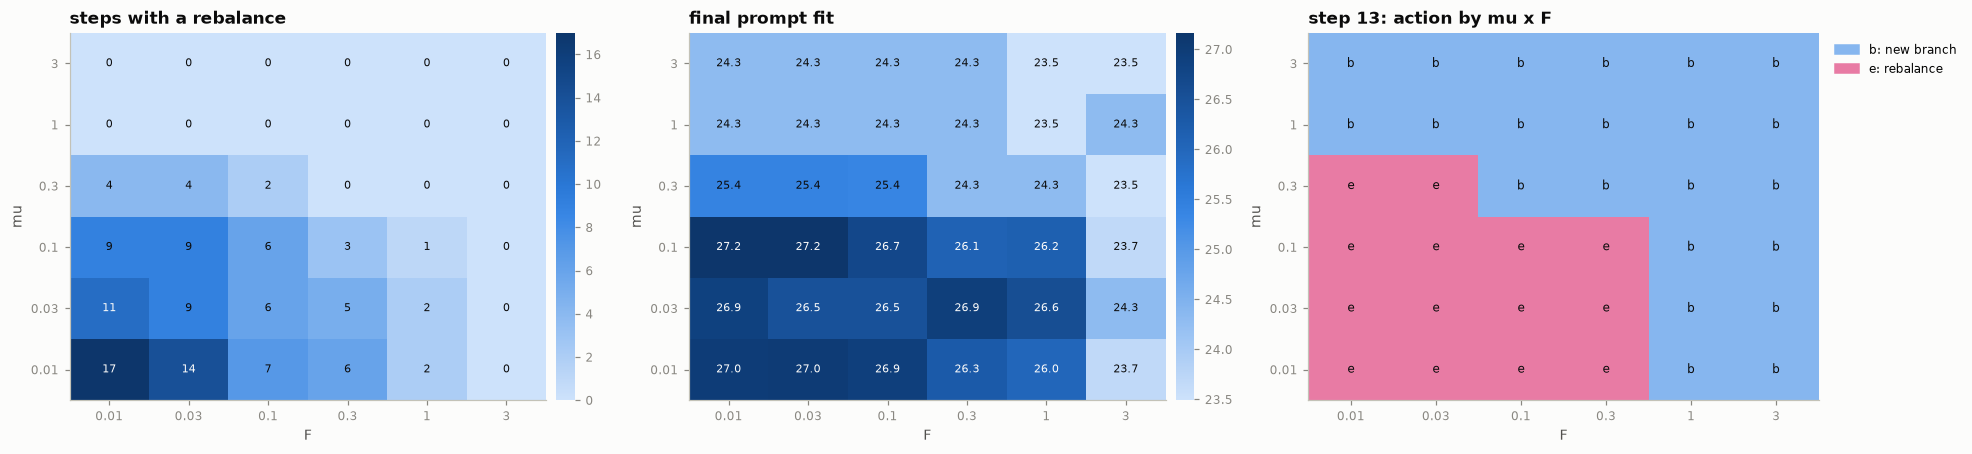

F,0.01,0.03,0.10,0.30,1.00,3.00
mu,,,,,,
0.01,17,14,7,6,2,0
0.03,11,9,6,5,2,0
0.10,9,9,6,3,1,0
0.30,4,4,2,0,0,0
1.00,0,0,0,0,0,0
3.00,0,0,0,0,0,0


F,0.01,0.03,0.10,0.30,1.00,3.00
mu,,,,,,
0.01,e,e,e,e,b,b
0.03,e,e,e,e,b,b
0.10,e,e,e,e,b,b
0.30,e,e,b,b,b,b
1.00,b,b,b,b,b,b
3.00,b,b,b,b,b,b


In [7]:
from forest.metrics import Scorer, summarize
from forest.simulate import run

scorer = Scorer(ctx.emb, cfg)
sweep = []
for mu, F in product(GRID, GRID):
    df, _ = run("ip", s, ctx, P.replace(mu=mu, F=F), golds[SESSION], scorer=scorer, guard=False)
    sm = summarize(df)
    sweep.append({"mu": mu, "F": F, "final_fit": sm["final_fit"], "disruption_w": sm["disruption_w"],
                  "rebalances": int((df["action"] == "e").sum())})
sweep = pd.DataFrame(sweep)
flip = pd.DataFrame([{"mu": mu, "F": F, "action": place(t["input"], P.replace(mu=mu, F=F)).action}
                     for mu, F in product(GRID, GRID)]).pivot(index="mu", columns="F", values="action")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
viz.heatmap(sweep.pivot(index="mu", columns="F", values="rebalances"), axes[0], title="steps with a rebalance",
            fmt="{:.0f}", xlabel="F", ylabel="mu")
viz.heatmap(sweep.pivot(index="mu", columns="F", values="final_fit"), axes[1], title="final prompt fit",
            fmt="{:.1f}", xlabel="F", ylabel="mu")
viz.action_heatmap(flip, axes[2], title=f"step {n.step}: action by mu x F", xlabel="F", ylabel="mu")
fig.tight_layout()
viz.save(fig, FIG / "ui_optimization_whatif.png")
plt.show()
display(sweep.pivot(index="mu", columns="F", values="rebalances"))
flip

## 7. Export for the prototype
The IP's forest after every step of `SESSION`, in the app's data model (concepts, trees, attempts,
messages; `forest/export.py`), and the parameters the prototype's planner uses.

In [8]:
out = FOR / SESSION / "ip"
path = export_sequence(session_forests["ip"], read_jsonl(out / "decisions.jsonl"), out,
                       {"session": SESSION, "method": "ip", "judge": ctx.judge.model, "embedding": ctx.emb.model})
params_out = ROOT / "outputs" / "export" / "planner-params.json"
write_json(params_out, {"source": "research/forest-building ui_optimization.ipynb", "ip": P.__dict__,
                        "scores": {"gamma": cfg["scores"]["gamma"]}, "disruption": cfg["disruption"],
                        "judge": {"backend": ctx.judge.backend, "model": ctx.judge.model},
                        "embedding": ctx.emb.model})
print("wrote", path.relative_to(ROOT), "and", params_out.relative_to(ROOT))
print("cache hits:", cache.store("embeddings").hits, "| misses:", cache.store("embeddings").misses,
      "| live judge calls:", cache.ledger().run_calls)

wrote outputs/forests/s1_focused/ip/app_sequence.json and outputs/export/planner-params.json
cache hits: 739 | misses: 0 | live judge calls: 0
